### PART - A

## Import and load dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

In [2]:
dataset = sns.load_dataset('titanic')

##  1 - Figure and Axes , age histogram

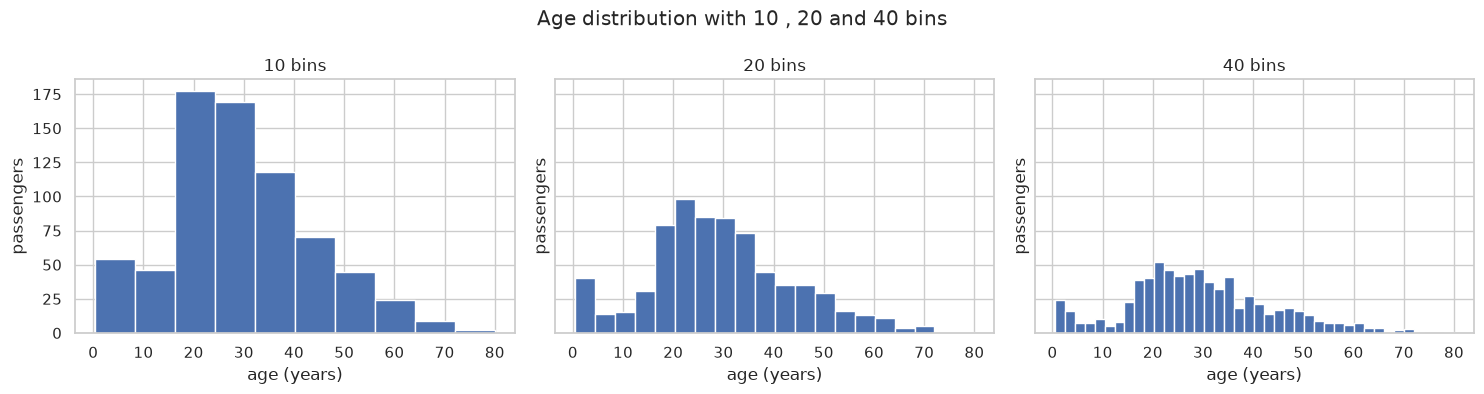

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, bins in zip(axes, [10, 20, 40]):
    ax.hist(dataset['age'].dropna(), bins=bins, color='#4c72b0', edgecolor='white')
    ax.set_title(f'{bins} bins')
    ax.set_xlabel('age (years)')
    ax.set_ylabel('passengers')

fig.suptitle('Age distribution with 10 , 20 and 40 bins')
fig.tight_layout()
plt.show()

# note to self : fig is the whole canvas , axes are the 3 boxes , sharey makes the 3 panels comparable

**What I see :** the age distribution is unimodal around 25-30 years with a small bump under 10 , and the shape is the same with 10 , 20 or 40 bins , only the noise changes.

**What it means :** age is slightly right-skewed (mean 29.7 > median 28) , and the 177 missing ages are simply absent from the plot.

**Limit :** a histogram pools every passenger , it hides the split by sex or class that actually drives survival.

##  2 - Passengers per class

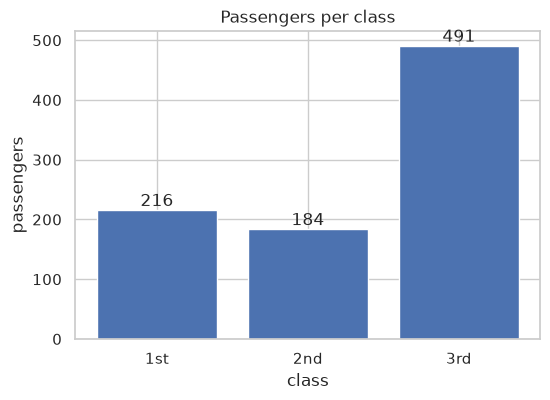

In [4]:
counts = dataset['pclass'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['1st', '2nd', '3rd'], counts.values, color='#4c72b0')
ax.bar_label(bars)
ax.set_title('Passengers per class')
ax.set_xlabel('class')
ax.set_ylabel('passengers')
plt.show()

# note to self : the heights are counts here , not rates , the labels avoid the classic "bar without numbers" trap

**What I see :** 491 passengers in 3rd class against 216 in 1st and 184 in 2nd , so more than half of the ship is 3rd class.

**What it means :** every class comparison has to be read with these counts , a rate computed on 184 people is noisier than one computed on 491.

**Limit :** counts say nothing about survival , the rates come in part B.

##  3 - Age against fare

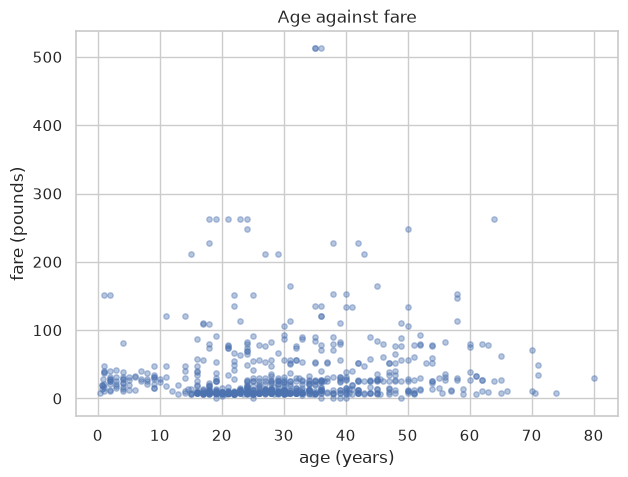

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(dataset['age'], dataset['fare'], s=15, alpha=0.4, color='#4c72b0')
ax.set_title('Age against fare')
ax.set_xlabel('age (years)')
ax.set_ylabel('fare (pounds)')
plt.show()

# note to self : matplotlib drops the NaN points silently , so the 177 missing ages are missing from this plot too

**What I see :** most points sit below 40 years and below 100 pounds , with a handful of fares above 250 and a hard ceiling at 512.

**What it means :** fare is heavily right-skewed and almost independent from age (r = 0.10).

**Limit :** the overplotting hides where the density really is , a log y-axis or a 2D histogram would read better.

##  4 - A 2x2 grid

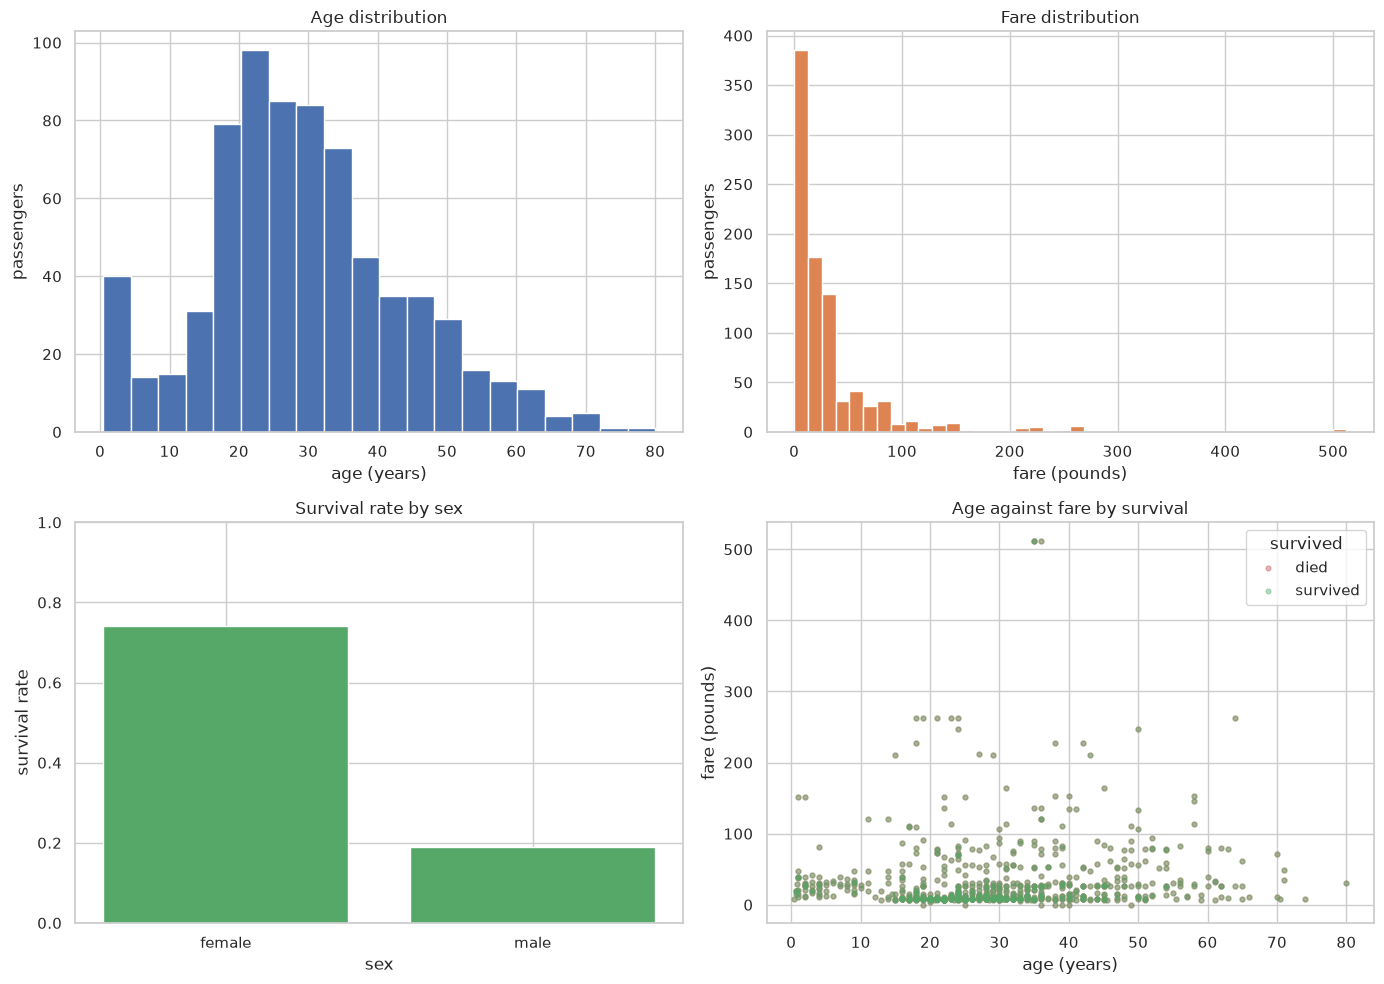

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].hist(dataset['age'].dropna(), bins=20, color='#4c72b0', edgecolor='white')
axes[0, 0].set_title('Age distribution')
axes[0, 0].set_xlabel('age (years)')
axes[0, 0].set_ylabel('passengers')

axes[0, 1].hist(dataset['fare'], bins=40, color='#dd8452', edgecolor='white')
axes[0, 1].set_title('Fare distribution')
axes[0, 1].set_xlabel('fare (pounds)')
axes[0, 1].set_ylabel('passengers')

survival_by_sex = dataset.groupby('sex')['survived'].mean()
axes[1, 0].bar(survival_by_sex.index, survival_by_sex.values, color='#55a868')
axes[1, 0].set_title('Survival rate by sex')
axes[1, 0].set_xlabel('sex')
axes[1, 0].set_ylabel('survival rate')
axes[1, 0].set_ylim(0, 1)

for survived, label, color in [(0, 'died', '#c44e52'), (1, 'survived', '#55a868')]:
    axes[1, 1].scatter(dataset['age'], dataset['fare'], s=12, alpha=0.4, label=label, color=color)

axes[1, 1].set_title('Age against fare by survival')
axes[1, 1].set_xlabel('age (years)')
axes[1, 1].set_ylabel('fare (pounds)')
axes[1, 1].legend(title='survived')

fig.tight_layout()
plt.show()

# note to self : four different questions on one canvas , each panel keeps its own title , labels and scale

**What I see :** four panels , the age distribution , the fare distribution , the survival rate by sex and age against fare coloured by survival.

**What it means :** the sex panel separates the two groups immediately , while the scatter shows that survivors are not separated by age.

**Limit :** each panel has its own scale so the bars cannot be compared across panels , and every panel drops the missing ages.